In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("../data/banking_customer_behaviour_synthetic.csv")

df.head()

,customer_id,age,gender,city_tier,account_type,tenure_months,monthly_income_inr,credit_score,digital_banking_user,monthly_transactions,digital_transaction_pct,average_transaction_value_inr,account_balance_inr,has_active_loan,loan_amount_inr,missed_loan_payments_12m,complaints_12m,satisfaction_score,churned
0,BK100001,70,Female,Metro,Current,69,80271.0,748.0,Yes,29,73.0,1360.85,89093.71,No,0.00,0,1,4.0,No
1,BK100002,64,Male,Tier 2,Current,29,65115.0,721.0,No,17,49.6,1555.08,124406.93,Yes,1211899.69,0,0,3.4,No
2,BK100003,42,Male,Tier 1,Savings,160,66463.0,793.0,Yes,45,89.6,1473.30,60365.13,No,0.00,0,0,4.2,No
3,BK100004,25,Male,Metro,Savings,35,50084.0,776.0,No,14,26.2,1629.04,220586.57,No,0.00,0,0,2.7,No
4,BK100005,70,Male,Tier 1,Salary,89,89117.0,668.0,No,12,29.7,613.57,293421.28,No,0.00,0,1,4.0,No


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (1200, 19)

Column Names:
['customer_id', 'age', 'gender', 'city_tier', 'account_type', 'tenure_months', 'monthly_income_inr', 'credit_score', 'digital_banking_user', 'monthly_transactions', 'digital_transaction_pct', 'average_transaction_value_inr', 'account_balance_inr', 'has_active_loan', 'loan_amount_inr', 'missed_loan_payments_12m', 'complaints_12m', 'satisfaction_score', 'churned']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    1200 non-null   object 
 1   age                            1200 non-null   int64  
 2   gender                         1200 non-null   object 
 3   city_tier                      1200 non-null   object 
 4   account_type                   1200 non-null   object 
 5   tenure_months                  1200 non-

In [5]:
print("Duplicate rows:", df.duplicated().sum())

print("\nDuplicate Customer IDs:", df["customer_id"].duplicated().sum())

print("\nMissing Values by Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Duplicate rows: 0

Duplicate Customer IDs: 0

Missing Values by Column:
customer_id                       0
age                               0
gender                            0
city_tier                         0
account_type                      0
tenure_months                     0
monthly_income_inr               30
credit_score                     21
digital_banking_user              0
monthly_transactions              0
digital_transaction_pct          24
average_transaction_value_inr     0
account_balance_inr               0
has_active_loan                   0
loan_amount_inr                   0
missed_loan_payments_12m          0
complaints_12m                    0
satisfaction_score               30
churned                           0
dtype: int64

Total Missing Values: 105


In [6]:
clean_df = df.copy()

columns_to_impute = [
    "monthly_income_inr",
    "credit_score",
    "digital_transaction_pct",
    "satisfaction_score"
]

for column in columns_to_impute:
    median_value = clean_df[column].median()
    clean_df[column] = clean_df[column].fillna(median_value)

print("Missing values after treatment:")
print(clean_df[columns_to_impute].isnull().sum())

print("\nTotal remaining missing values:",
      clean_df.isnull().sum().sum())

Missing values after treatment:
monthly_income_inr         0
credit_score               0
digital_transaction_pct    0
satisfaction_score         0
dtype: int64

Total remaining missing values: 0


In [7]:
clean_df.describe().round(2)


,age,tenure_months,monthly_income_inr,credit_score,monthly_transactions,digital_transaction_pct,average_transaction_value_inr,account_balance_inr,loan_amount_inr,missed_loan_payments_12m,complaints_12m,satisfaction_score
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,45.69,92.77,62231.58,710.26,27.40,65.70,1520.98,161038.28,265788.75,0.20,0.49,3.99
std,14.35,51.29,22885.42,56.08,8.22,24.06,1044.63,108016.49,454565.99,0.53,0.72,0.71
min,21.00,1.00,15000.00,537.00,4.00,0.00,169.02,500.00,0.00,0.00,0.00,1.10
25%,34.00,50.00,47203.50,673.00,22.00,52.20,830.90,73155.69,0.00,0.00,0.00,3.50
50%,46.00,93.00,61609.00,709.00,28.00,71.30,1275.58,141368.92,0.00,0.00,0.00,4.00
75%,59.00,138.00,76990.25,748.00,33.00,82.90,1880.44,232111.21,431635.66,0.00,1.00,4.50
max,70.00,180.00,132887.00,850.00,48.00,100.00,8404.25,566924.33,2500000.00,4.00,5.00,5.00


In [8]:
clean_df["age_group"] = pd.cut(
    clean_df["age"],
    bins=[20, 30, 40, 50, 60, 70],
    labels=["21-30", "31-40", "41-50", "51-60", "61-70"]
)

age_analysis = clean_df.groupby(
    "age_group", observed=False
).agg(
    customer_count=("customer_id", "count"),
    average_income=("monthly_income_inr", "mean"),
    average_satisfaction=("satisfaction_score", "mean")
).round(2)

age_analysis

,customer_count,average_income,average_satisfaction
age_group,,,
21-30,237,63692.10,3.99
31-40,244,58631.54,4.00
41-50,240,62620.68,4.05
51-60,234,64016.25,4.02
61-70,245,62318.38,3.87


In [9]:
print("CUSTOMERS BY ACCOUNT TYPE")

account_distribution = clean_df["account_type"].value_counts()

print(account_distribution)

print("\nCUSTOMERS BY CITY TIER")

city_distribution = clean_df["city_tier"].value_counts()

print(city_distribution)

CUSTOMERS BY ACCOUNT TYPE
account_type
Savings    669
Salary     315
Current    216
Name: count, dtype: int64

CUSTOMERS BY CITY TIER
city_tier
Metro     348
Tier 1    340
Tier 2    319
Tier 3    193
Name: count, dtype: int64


In [10]:
transaction_analysis = clean_df.groupby(
    "account_type"
).agg(
    customer_count=("customer_id", "count"),
    average_transactions=("monthly_transactions", "mean"),
    average_transaction_value=("average_transaction_value_inr", "mean"),
    average_balance=("account_balance_inr", "mean")
).round(2)

transaction_analysis

,customer_count,average_transactions,average_transaction_value,average_balance
account_type,,,,
Current,216,27.72,1562.85,168245.33
Salary,315,27.66,1477.64,163086.50
Savings,669,27.18,1527.88,157746.93


In [11]:
digital_analysis = clean_df.groupby(
    "digital_banking_user"
).agg(
    customer_count=("customer_id", "count"),
    average_transactions=("monthly_transactions", "mean"),
    average_digital_pct=("digital_transaction_pct", "mean"),
    average_satisfaction=("satisfaction_score", "mean"),
    average_balance=("account_balance_inr", "mean")
).round(2)

digital_analysis

,customer_count,average_transactions,average_digital_pct,average_satisfaction,average_balance
digital_banking_user,,,,,
No,258,15.71,29.13,3.97,167886.05
Yes,942,30.60,75.71,3.99,159162.77


In [12]:
loan_analysis = clean_df.groupby(
    "has_active_loan"
).agg(
    customer_count=("customer_id", "count"),
    average_loan_amount=("loan_amount_inr", "mean"),
    total_missed_payments=("missed_loan_payments_12m", "sum"),
    average_missed_payments=("missed_loan_payments_12m", "mean"),
    average_credit_score=("credit_score", "mean")
).round(2)

loan_analysis

,customer_count,average_loan_amount,total_missed_payments,average_missed_payments,average_credit_score
has_active_loan,,,,,
No,768,0.00,0,0.00,708.84
Yes,432,738302.09,238,0.55,712.79


In [13]:
churn_analysis = clean_df.groupby(
    "churned"
).agg(
    customer_count=("customer_id", "count"),
    average_transactions=("monthly_transactions", "mean"),
    average_complaints=("complaints_12m", "mean"),
    average_satisfaction=("satisfaction_score", "mean"),
    average_tenure=("tenure_months", "mean"),
    average_missed_payments=("missed_loan_payments_12m", "mean")
).round(2)

churn_analysis

,customer_count,average_transactions,average_complaints,average_satisfaction,average_tenure,average_missed_payments
churned,,,,,,
No,1154,27.51,0.48,3.99,92.89,0.20
Yes,46,24.67,0.74,3.80,89.70,0.26


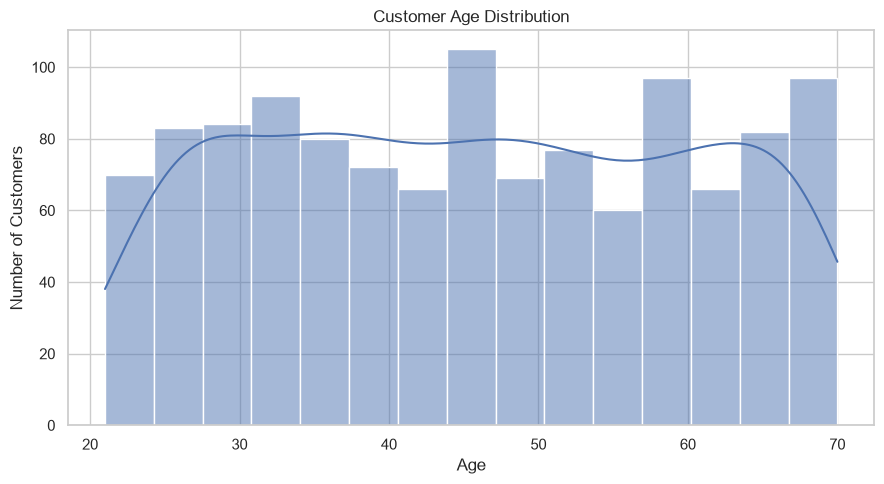

In [14]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=clean_df,
    x="age",
    bins=15,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    "../outputs/charts/customer_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

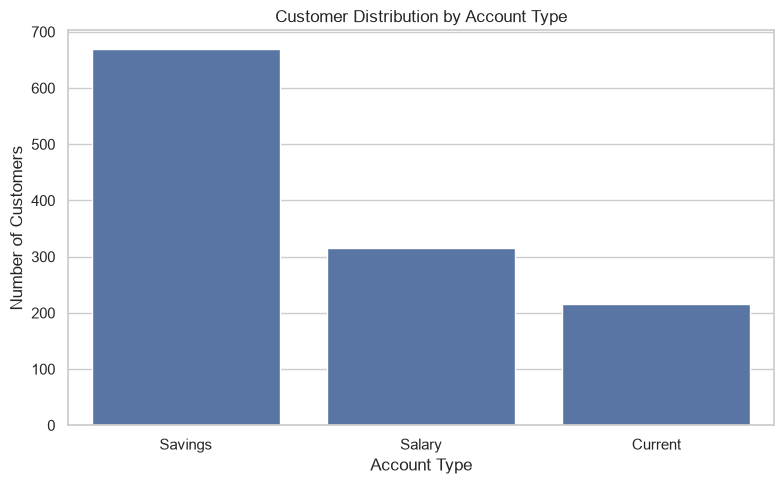

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=clean_df,
    x="account_type",
    order=clean_df["account_type"].value_counts().index
)

plt.title("Customer Distribution by Account Type")
plt.xlabel("Account Type")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/account_type_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

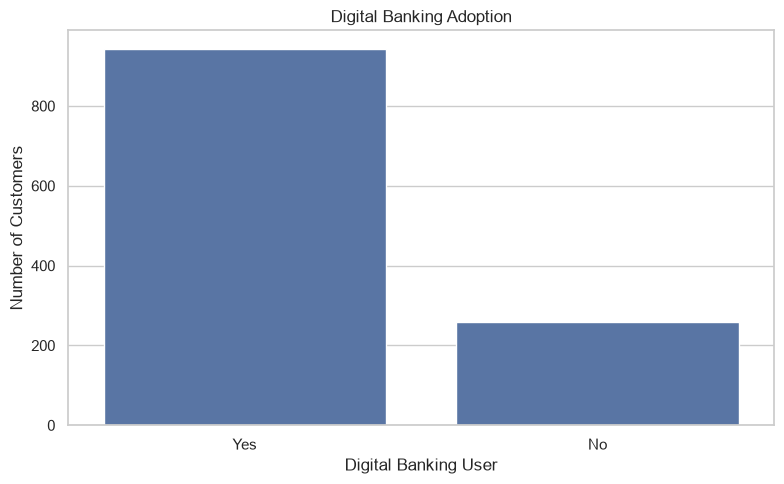

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=clean_df,
    x="digital_banking_user",
    order=["Yes", "No"]
)

plt.title("Digital Banking Adoption")
plt.xlabel("Digital Banking User")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/digital_banking_adoption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

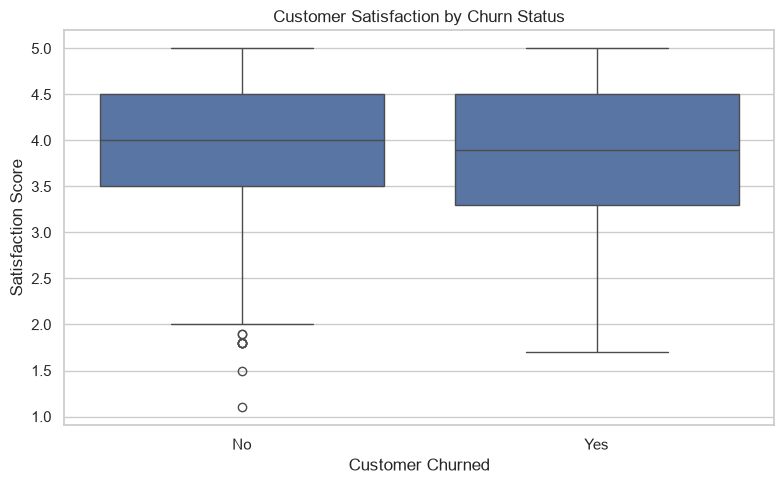

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean_df,
    x="churned",
    y="satisfaction_score"
)

plt.title("Customer Satisfaction by Churn Status")
plt.xlabel("Customer Churned")
plt.ylabel("Satisfaction Score")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/satisfaction_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

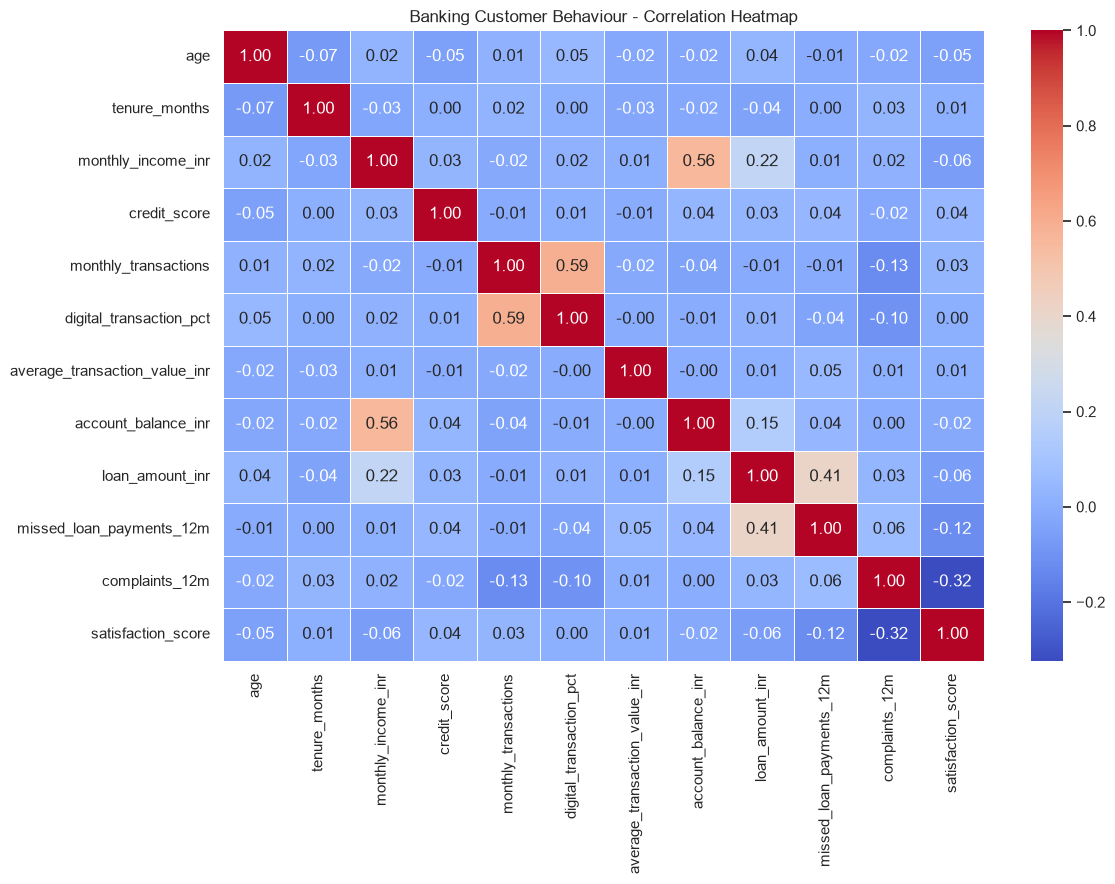

In [18]:
correlation_columns = [
    "age",
    "tenure_months",
    "monthly_income_inr",
    "credit_score",
    "monthly_transactions",
    "digital_transaction_pct",
    "average_transaction_value_inr",
    "account_balance_inr",
    "loan_amount_inr",
    "missed_loan_payments_12m",
    "complaints_12m",
    "satisfaction_score"
]

correlation_matrix = clean_df[correlation_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Banking Customer Behaviour - Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    "../outputs/charts/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
from pathlib import Path

report = """
# Banking Customer Behaviour Analysis
## Business Insights Report

### 1. Project Overview
- Dataset: Synthetic banking customer data
- Total customers: 1,200
- Total columns: 19
- Project type: Exploratory Data Analysis (EDA)
- Tools: Python, Pandas, NumPy, Matplotlib, Seaborn

### 2. Data Quality
- Duplicate rows: 0
- Duplicate customer IDs: 0
- Missing values initially: 105
- Missing values after treatment: 0
- Median imputation was used for selected numerical columns.

### 3. Customer Demographics
- Average customer age: 45.69 years
- Largest age group: 61–70 years (245 customers)
- Highest average income: Age group 51–60
- Highest average satisfaction: Age group 41–50

### 4. Account Distribution
- Savings: 669 customers (55.75%)
- Salary: 315 customers (26.25%)
- Current: 216 customers (18.00%)
- Metro customers: 348

### 5. Transaction Behaviour
- Current account customers had the highest average monthly transactions.
- Current account customers also had the highest average transaction value.
- Savings accounts represented the largest customer segment.

### 6. Digital Banking
- Digital banking users: 942 (78.5%)
- Non-digital users: 258 (21.5%)
- Average monthly transactions:
  - Digital users: 30.60
  - Non-digital users: 15.71

### 7. Loan Behaviour
- Customers with active loans: 432 (36%)
- Average loan amount among active-loan group: INR 738,302.09
- Total missed payments in active-loan group: 238
- Average missed payments in active-loan group: 0.55

### 8. Customer Churn
- Churned customers: 46
- Churn rate: 3.83%
- Churned customers had:
  - Lower average monthly transactions
  - More average complaints
  - Lower average satisfaction
  - More average missed payments

### 9. Correlation Findings
- Monthly transactions and digital transaction percentage: 0.59
- Monthly income and account balance: 0.56
- Loan amount and missed payments: 0.41
- Complaints and satisfaction: -0.32

### 10. Business Recommendations
1. Improve support for customers who report complaints.
2. Encourage digital banking adoption among non-digital customers.
3. Monitor customers with repeated missed loan payments.
4. Investigate factors associated with lower customer satisfaction.
5. Develop customer retention strategies for potentially at-risk customers.

### 11. Conclusion
The analysis highlights customer demographics, account preferences,
transaction activity, digital adoption, loan behaviour and churn patterns.

The findings can help a bank identify areas for improving customer
experience, digital engagement and retention.

Note: This is a synthetic practice dataset. Findings do not represent
the performance of an actual bank. Correlation does not imply causation.
"""

report_path = Path("../outputs/reports/business_insights.md")
report_path.write_text(report, encoding="utf-8")

print("Business insights report saved successfully!")
print("File:", report_path)

Business insights report saved successfully!
File: ..\outputs\reports\business_insights.md


In [20]:
from pathlib import Path

cleaned_file = Path(
    "../outputs/banking_customer_behaviour_cleaned.csv"
)

clean_df.to_csv(cleaned_file, index=False)

print("Cleaned dataset exported successfully!")
print("File:", cleaned_file)
print("Rows:", clean_df.shape[0])
print("Columns:", clean_df.shape[1])
print("Remaining missing values:", clean_df.isnull().sum().sum())

Cleaned dataset exported successfully!
File: ..\outputs\banking_customer_behaviour_cleaned.csv
Rows: 1200
Columns: 20
Remaining missing values: 0


In [21]:
from pathlib import Path

readme_path = Path("../README.md")

readme_path.write_text(
    "# Banking Customer Behaviour Analysis\n\n"
    "Project documentation will be added here.\n",
    encoding="utf-8"
)

print("README.md file created successfully!")
print("Is file:", readme_path.is_file())

README.md file created successfully!
Is file: True


In [22]:
from pathlib import Path

readme_content = """
# Banking Customer Behaviour Analysis

## Project Overview
Exploratory Data Analysis of 1,200 synthetic banking customer records using Python.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Project Objectives
- Analyse customer demographics.
- Understand account and transaction behaviour.
- Explore digital banking adoption.
- Analyse loan behaviour and missed payments.
- Investigate customer churn.
- Identify correlations between numerical variables.

## Data Cleaning
- Original records: 1,200
- Original columns: 19
- Duplicate rows: 0
- Duplicate customer IDs: 0
- Initial missing values: 105
- Missing values after treatment: 0
- Median imputation used for selected numerical columns.

## Key Findings

### Customer Demographics
- Average age: 45.69 years.
- Largest age group: 61–70 years (245 customers).

### Account Distribution
- Savings: 669 (55.75%)
- Salary: 315 (26.25%)
- Current: 216 (18%)

### Digital Banking
- Digital users: 942 (78.5%)
- Non-digital users: 258 (21.5%)
- Average monthly transactions: 30.60 for digital users and 15.71 for non-digital users.

### Loan Behaviour
- Active loan customers: 432 (36%)
- Average loan amount among active loan customers: INR 738,302.09.
- Total missed payments: 238.

### Customer Churn
- Churned customers: 46.
- Churn rate: 3.83%.
- Churned customers had more complaints and slightly lower satisfaction.

### Correlation Findings
- Monthly transactions and digital transaction percentage: 0.59.
- Monthly income and account balance: 0.56.
- Loan amount and missed payments: 0.41.
- Complaints and satisfaction: -0.32.

## Visualizations
1. Customer Age Distribution
2. Customer Distribution by Account Type
3. Digital Banking Adoption
4. Customer Satisfaction by Churn Status
5. Correlation Heatmap

## Business Recommendations
- Improve customer support.
- Encourage digital banking adoption.
- Monitor missed loan payments.
- Investigate customer dissatisfaction.
- Develop customer retention strategies.

## Limitations
- The dataset is synthetic.
- Correlation does not imply causation.
- Findings do not represent actual bank performance.

## Conclusion
This project demonstrates Python data cleaning, exploratory data analysis,
data visualization, customer behaviour analysis and business insight generation.

## Privacy
This is a local practice project and is not intended for public upload.
"""

readme_path = Path("../README.md")
readme_path.write_text(readme_content, encoding="utf-8")

print("README updated successfully!")
print("File exists:", readme_path.is_file())
print("File size:", readme_path.stat().st_size, "bytes")

README updated successfully!
File exists: True
File size: 2498 bytes
